# Exploratory Data Analysis (EDA) — Olist Delivery Time Prediction

Mục tiêu của notebook này:
1. Kiểm tra cấu trúc, kích thước, giá trị thiếu (missing values) và chất lượng của các bảng dữ liệu Olist.
2. Định nghĩa và phân tích biến mục tiêu `delivery_time_days` (số ngày giao hàng thực tế từ lúc đặt hàng).
3. Đánh giá **Baseline** hiện tại của Olist (`order_estimated_delivery_date`).
4. Phân tích các yếu tố ảnh hưởng đến thời gian giao hàng: **Thời gian (mùa vụ)**, **Địa lý (bang, khoảng cách Haversine)**, **Sản phẩm & Đơn hàng**, **Thanh toán**.
5. Xuất các biểu đồ chất lượng cao vào `MachineLearning/eda_figures/` để phục vụ viết báo cáo.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RAW_DIR = 'raw'
FIG_DIR = 'eda_figures'
os.makedirs(FIG_DIR, exist_ok=True)
print('Setup completed!')

Setup completed!


## 1. Load & Kiểm tra tổng quan các bảng dữ liệu

In [2]:
orders = pd.read_csv(os.path.join(RAW_DIR, 'olist_orders_dataset.csv'))
order_items = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_items_dataset.csv'))
customers = pd.read_csv(os.path.join(RAW_DIR, 'olist_customers_dataset.csv'))
sellers = pd.read_csv(os.path.join(RAW_DIR, 'olist_sellers_dataset.csv'))
products = pd.read_csv(os.path.join(RAW_DIR, 'olist_products_dataset.csv'))
geolocation = pd.read_csv(os.path.join(RAW_DIR, 'olist_geolocation_dataset.csv'))
payments = pd.read_csv(os.path.join(RAW_DIR, 'olist_order_payments_dataset.csv'))
cat_trans = pd.read_csv(os.path.join(RAW_DIR, 'product_category_name_translation.csv'))

tables = {
    'orders': orders,
    'order_items': order_items,
    'customers': customers,
    'sellers': sellers,
    'products': products,
    'geolocation': geolocation,
    'payments': payments,
    'cat_trans': cat_trans,
}

summary_rows = []
for name, df in tables.items():
    summary_rows.append({
        'Table': name,
        'Rows': df.shape[0],
        'Cols': df.shape[1],
        'Missing Cells': int(df.isna().sum().sum()),
        'Duplicate Rows': int(df.duplicated().sum())
    })
pd.DataFrame(summary_rows)

,Table,Rows,Cols,Missing Cells,Duplicate Rows
0,orders,99441,8,4908,0
1,order_items,112650,7,0,0
2,customers,99441,5,0,0
3,sellers,3095,4,0,0
4,products,32951,9,2448,0
5,geolocation,1000163,5,0,261831
6,payments,103886,5,0,0
7,cat_trans,71,2,0,0


In [3]:
# Kiểm tra phân phối trạng thái đơn hàng (order_status)
status_counts = orders['order_status'].value_counts()
status_pct = (orders['order_status'].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({'Count': status_counts, 'Percentage (%)': status_pct})

,Count,Percentage (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


## 2. Làm sạch bảng `orders` & Phân tích biến mục tiêu `delivery_time_days`

- Chỉ giữ các đơn hàng có `order_status == 'delivered'`.
- Chuyển đổi các cột thời gian sang `datetime`.
- Tính `delivery_time_days = (order_delivered_customer_date - order_purchase_timestamp) / 86400`.
- Tính `estimated_days = (order_estimated_delivery_date - order_purchase_timestamp) / 86400` (Baseline của Olist).

In [4]:
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

df_deliv = orders[orders['order_status'] == 'delivered'].copy()
print(f'Delivered orders: {len(df_deliv):,}')
print('Missing values in delivered orders:')
print(df_deliv[date_cols].isna().sum())

# Loại bỏ các dòng thiếu ngày giao hàng thực tế
df_deliv = df_deliv.dropna(subset=['order_delivered_customer_date', 'order_purchase_timestamp']).copy()

df_deliv['delivery_time_days'] = (
    df_deliv['order_delivered_customer_date'] - df_deliv['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

df_deliv['estimated_days'] = (
    df_deliv['order_estimated_delivery_date'] - df_deliv['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

df_deliv['approval_delay_hours'] = (
    df_deliv['order_approved_at'] - df_deliv['order_purchase_timestamp']
).dt.total_seconds() / 3600.0

print(f'\nMin delivery_time_days: {df_deliv["delivery_time_days"].min():.4f}')
print(f'Orders with delivery_time_days <= 0: {(df_deliv["delivery_time_days"] <= 0).sum()}')
print(f'Orders with delivery_time_days > 60: {(df_deliv["delivery_time_days"] > 60).sum()}')
print(f'Orders with delivery_time_days > 90: {(df_deliv["delivery_time_days"] > 90).sum()}')

df_deliv = df_deliv[df_deliv['delivery_time_days'] > 0].copy()
df_deliv['delivery_time_days'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

Delivered orders: 96,478
Missing values in delivered orders:
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      2
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Min delivery_time_days: 0.5334
Orders with delivery_time_days <= 0: 0
Orders with delivery_time_days > 60: 306
Orders with delivery_time_days > 90: 77


count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
90%         23.096377
95%         29.274046
99%         46.050262
max        209.628611
Name: delivery_time_days, dtype: float64

In [5]:
# Đánh giá Baseline của Olist (order_estimated_delivery_date)
olist_mae = mean_absolute_error(df_deliv['delivery_time_days'], df_deliv['estimated_days'])
olist_rmse = np.sqrt(mean_squared_error(df_deliv['delivery_time_days'], df_deliv['estimated_days']))
late_rate = (df_deliv['delivery_time_days'] > df_deliv['estimated_days']).mean() * 100
mean_bias = (df_deliv['estimated_days'] - df_deliv['delivery_time_days']).mean()

print(f'Olist Estimated Baseline -> MAE: {olist_mae:.3f} days | RMSE: {olist_rmse:.3f} days')
print(f'Olist Average Over-estimation (Buffer): +{mean_bias:.2f} days | Late Delivery Rate: {late_rate:.2f}%')

Olist Estimated Baseline -> MAE: 12.728 days | RMSE: 15.122 days
Olist Average Over-estimation (Buffer): +11.18 days | Late Delivery Rate: 8.11%


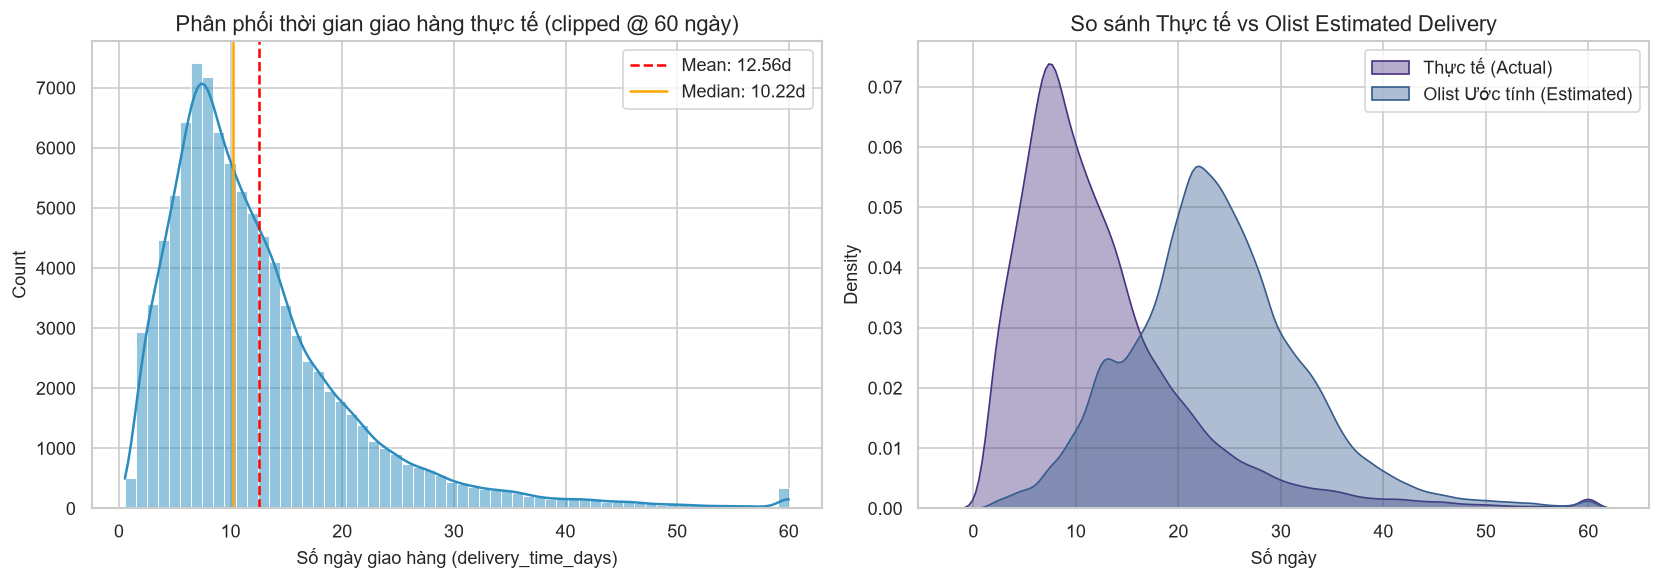

In [6]:
# Vẽ phân phối delivery_time_days vs estimated_days
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_deliv['delivery_time_days'].clip(upper=60), bins=60, kde=True, ax=axes[0], color='#2b8cbe')
axes[0].axvline(df_deliv['delivery_time_days'].mean(), color='red', linestyle='--', label=f"Mean: {df_deliv['delivery_time_days'].mean():.2f}d")
axes[0].axvline(df_deliv['delivery_time_days'].median(), color='orange', linestyle='-', label=f"Median: {df_deliv['delivery_time_days'].median():.2f}d")
axes[0].set_title('Phân phối thời gian giao hàng thực tế (clipped @ 60 ngày)')
axes[0].set_xlabel('Số ngày giao hàng (delivery_time_days)')
axes[0].legend()

sns.kdeplot(df_deliv['delivery_time_days'].clip(upper=60), ax=axes[1], label='Thực tế (Actual)', fill=True, alpha=0.4)
sns.kdeplot(df_deliv['estimated_days'].clip(upper=60), ax=axes[1], label='Olist Ước tính (Estimated)', fill=True, alpha=0.4)
axes[1].set_title('So sánh Thực tế vs Olist Estimated Delivery')
axes[1].set_xlabel('Số ngày')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_target_distribution.png'), bbox_inches='tight')
plt.show()

## 3. Phân tích theo Thời gian (Mùa vụ & Sự kiện đặc biệt)

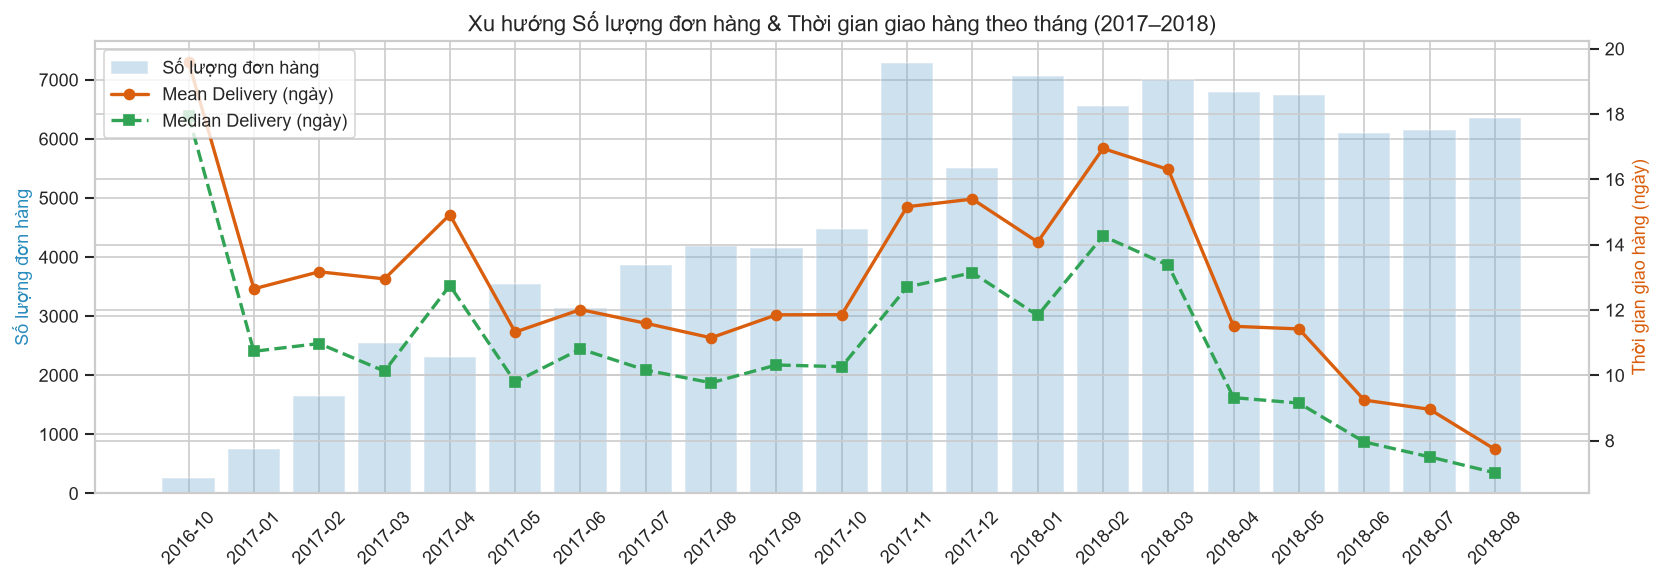

Date range: 2016-09-15 12:16:38 -> 2018-08-29 15:00:37


In [7]:
df_deliv['purchase_month'] = df_deliv['order_purchase_timestamp'].dt.to_period('M').astype(str)
df_deliv['purchase_dayofweek'] = df_deliv['order_purchase_timestamp'].dt.dayofweek
df_deliv['purchase_hour'] = df_deliv['order_purchase_timestamp'].dt.hour

monthly = df_deliv.groupby('purchase_month').agg(
    order_count=('order_id', 'count'),
    mean_delivery=('delivery_time_days', 'mean'),
    median_delivery=('delivery_time_days', 'median')
).reset_index()

# Lọc các tháng có đủ dữ liệu (>= 100 đơn) để tránh nhiễu tháng đầu/cuối
monthly_valid = monthly[monthly['order_count'] >= 100]

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly_valid['purchase_month'], monthly_valid['order_count'], alpha=0.35, color='#74a9cf', label='Số lượng đơn hàng')
ax1.set_ylabel('Số lượng đơn hàng', color='#2b8cbe')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly_valid['purchase_month'], monthly_valid['mean_delivery'], color='#d95f0e', marker='o', linewidth=2, label='Mean Delivery (ngày)')
ax2.plot(monthly_valid['purchase_month'], monthly_valid['median_delivery'], color='#31a354', marker='s', linestyle='--', linewidth=2, label='Median Delivery (ngày)')
ax2.set_ylabel('Thời gian giao hàng (ngày)', color='#d95f0e')

plt.title('Xu hướng Số lượng đơn hàng & Thời gian giao hàng theo tháng (2017–2018)')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_monthly_trends.png'), bbox_inches='tight')
plt.show()

print(f"Date range: {df_deliv['order_purchase_timestamp'].min()} -> {df_deliv['order_purchase_timestamp'].max()}")

## 4. Merge các bảng & Phân tích Địa lý (Geo, Haversine Distance, State)

In [8]:
# 1. Làm sạch Geolocation: giữ tọa độ trong lãnh thổ Brazil và lấy median theo zip_code_prefix
geo_clean = geolocation[
    (geolocation['geolocation_lat'].between(-35.0, 6.0)) &
    (geolocation['geolocation_lng'].between(-75.0, -30.0))
].groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].median().reset_index()

# 2. Aggregate order_items theo order_id + join products & sellers
items_enriched = order_items.merge(products, on='product_id', how='left')
items_enriched = items_enriched.merge(sellers, on='seller_id', how='left')
items_enriched['shipping_limit_date'] = pd.to_datetime(items_enriched['shipping_limit_date'])
items_enriched['product_volume_cm3'] = (
    items_enriched['product_length_cm'] *
    items_enriched['product_height_cm'] *
    items_enriched['product_width_cm']
)

# Giữ seller chính (item đầu tiên) để tính khoảng cách đại diện cho đơn hàng
order_agg = items_enriched.groupby('order_id').agg(
    total_items=('order_item_id', 'count'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    num_unique_sellers=('seller_id', 'nunique'),
    num_unique_products=('product_id', 'nunique'),
    total_weight_g=('product_weight_g', 'sum'),
    total_volume_cm3=('product_volume_cm3', 'sum'),
    primary_seller_zip=('seller_zip_code_prefix', 'first'),
    primary_seller_state=('seller_state', 'first'),
    primary_category=('product_category_name', 'first'),
    min_shipping_limit=('shipping_limit_date', 'min')
).reset_index()

# 3. Aggregate payments theo order_id
pay_agg = payments.groupby('order_id').agg(
    primary_payment_type=('payment_type', 'first'),
    max_installments=('payment_installments', 'max'),
    total_payment_value=('payment_value', 'sum')
).reset_index()

# 4. Merge thành bảng phân tích cấp đơn hàng
df_eda = df_deliv.merge(customers, on='customer_id', how='left')
df_eda = df_eda.merge(order_agg, on='order_id', how='left')
df_eda = df_eda.merge(pay_agg, on='order_id', how='left')
df_eda = df_eda.merge(cat_trans, left_on='primary_category', right_on='product_category_name', how='left')

# Join tọa độ customer và seller
df_eda = df_eda.merge(
    geo_clean.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                              'geolocation_lat': 'cust_lat', 'geolocation_lng': 'cust_lng'}),
    on='customer_zip_code_prefix', how='left'
)
df_eda = df_eda.merge(
    geo_clean.rename(columns={'geolocation_zip_code_prefix': 'primary_seller_zip',
                              'geolocation_lat': 'sell_lat', 'geolocation_lng': 'sell_lng'}),
    on='primary_seller_zip', how='left'
)

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df_eda['haversine_km'] = haversine_km(
    df_eda['sell_lat'], df_eda['sell_lng'], df_eda['cust_lat'], df_eda['cust_lng']
)
df_eda['is_same_state'] = (df_eda['customer_state'] == df_eda['primary_seller_state']).astype(int)
df_eda['freight_ratio'] = df_eda['total_freight'] / (df_eda['total_price'] + 1e-5)
df_eda['prep_sla_days'] = (df_eda['min_shipping_limit'] - df_eda['order_purchase_timestamp']).dt.total_seconds() / 86400.0

print(f'Merged EDA dataframe shape: {df_eda.shape}')
print(f'Missing haversine_km: {df_eda["haversine_km"].isna().sum()} ({df_eda["haversine_km"].isna().mean()*100:.2f}%)')

Merged EDA dataframe shape: (96470, 42)
Missing haversine_km: 479 (0.50%)


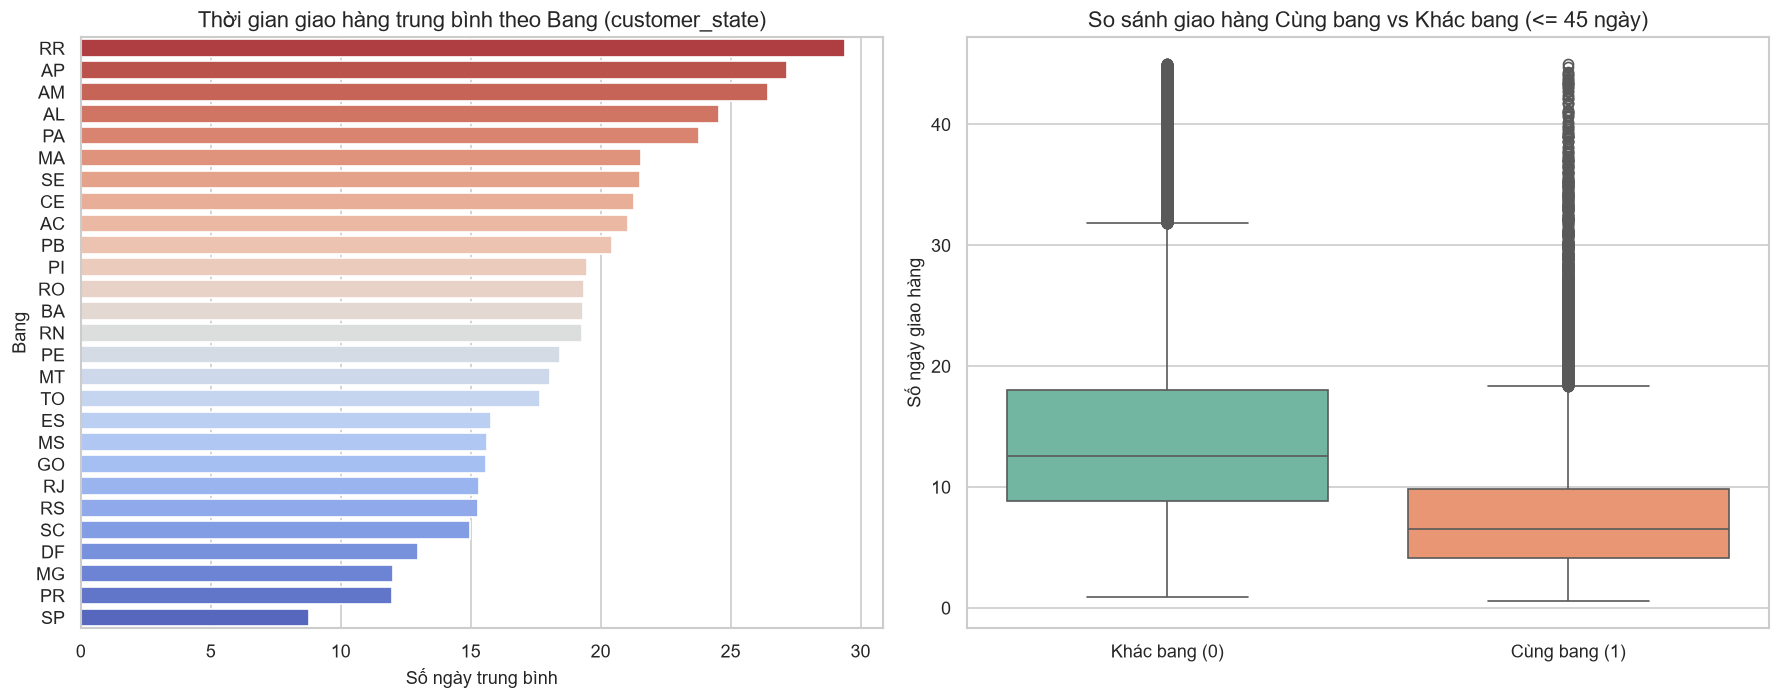

,count,mean,median
customer_state,,,
RR,41,29.387546,25.007303
AP,67,27.185068,24.347025
AM,145,26.425991,25.875139
AL,397,24.543855,22.332917
PA,946,23.772917,21.078391


,count,mean,median
customer_state,,,
SC,3546,14.954783,13.014352
DF,2080,12.967568,11.364925
MG,11354,12.008666,10.313513
PR,4923,11.991582,10.425509
SP,40494,8.761386,7.210272


In [9]:
# Thời gian giao hàng theo Bang của khách hàng (customer_state) & Same-State vs Cross-State
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

state_stats = df_eda.groupby('customer_state')['delivery_time_days'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False)
sns.barplot(x=state_stats['mean'], y=state_stats.index, ax=axes[0], palette='coolwarm_r')
axes[0].set_title('Thời gian giao hàng trung bình theo Bang (customer_state)')
axes[0].set_xlabel('Số ngày trung bình')
axes[0].set_ylabel('Bang')

sns.boxplot(data=df_eda[df_eda['delivery_time_days'] <= 45], x='is_same_state', y='delivery_time_days', ax=axes[1], palette='Set2')
axes[1].set_xticklabels(['Khác bang (0)', 'Cùng bang (1)'])
axes[1].set_title('So sánh giao hàng Cùng bang vs Khác bang (<= 45 ngày)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Số ngày giao hàng')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_geography_state.png'), bbox_inches='tight')
plt.show()

display(state_stats.head(5))
display(state_stats.tail(5))

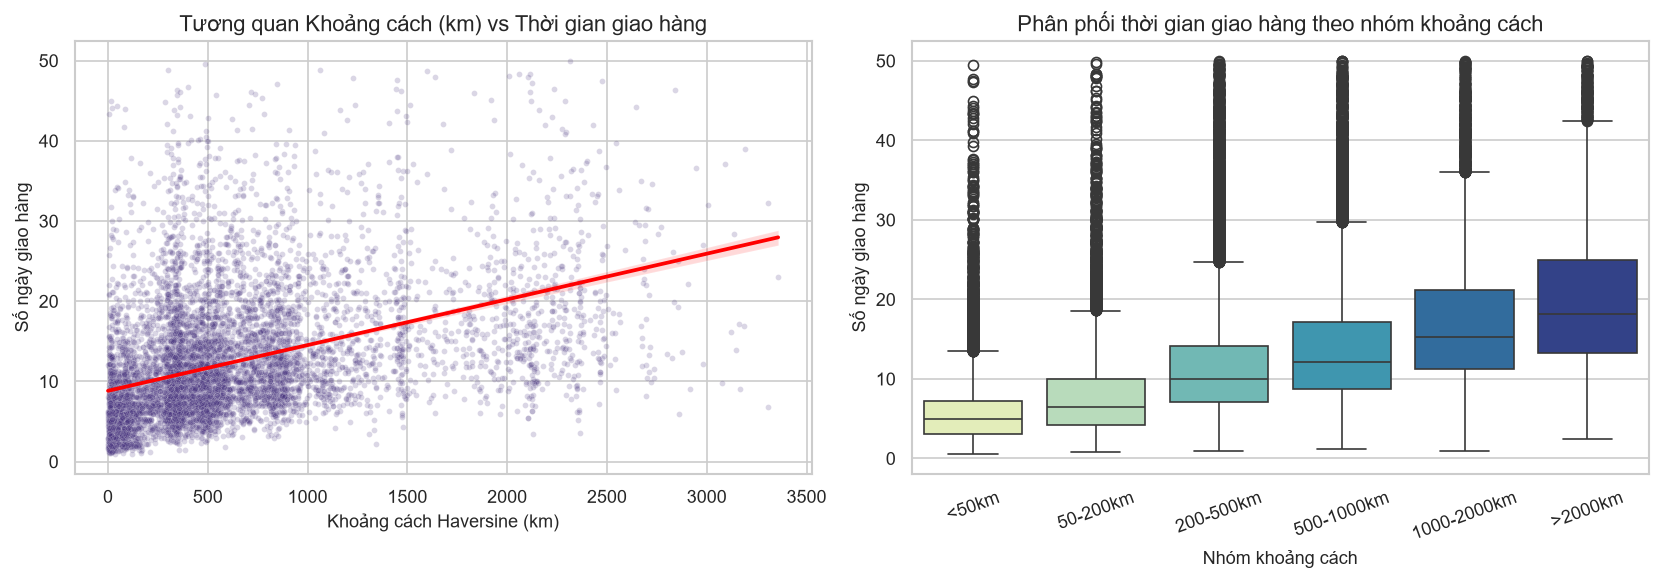

In [10]:
# Mối quan hệ giữa Khoảng cách Haversine và Thời gian giao hàng
geo_valid = df_eda.dropna(subset=['haversine_km']).copy()
geo_valid['dist_bin'] = pd.cut(
    geo_valid['haversine_km'],
    bins=[-1, 50, 200, 500, 1000, 2000, 5000],
    labels=['<50km', '50-200km', '200-500km', '500-1000km', '1000-2000km', '>2000km']
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample_df = geo_valid[geo_valid['delivery_time_days'] <= 50].sample(min(8000, len(geo_valid)), random_state=42)
sns.scatterplot(data=sample_df, x='haversine_km', y='delivery_time_days', alpha=0.2, s=12, ax=axes[0])
sns.regplot(data=sample_df, x='haversine_km', y='delivery_time_days', scatter=False, color='red', ax=axes[0])
axes[0].set_title('Tương quan Khoảng cách (km) vs Thời gian giao hàng')
axes[0].set_xlabel('Khoảng cách Haversine (km)')
axes[0].set_ylabel('Số ngày giao hàng')

sns.boxplot(data=geo_valid[geo_valid['delivery_time_days'] <= 50], x='dist_bin', y='delivery_time_days', ax=axes[1], palette='YlGnBu')
axes[1].set_title('Phân phối thời gian giao hàng theo nhóm khoảng cách')
axes[1].set_xlabel('Nhóm khoảng cách')
axes[1].set_ylabel('Số ngày giao hàng')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_distance_vs_delivery.png'), bbox_inches='tight')
plt.show()

## 5. Phân tích Sản phẩm, Thanh toán & Ma trận tương quan

,orders,mean_approval_hours,mean_delivery_days
primary_payment_type,,,
credit_card,73213,4.416922,12.347432
boleto,19191,33.009643,13.491950
voucher,2582,8.290744,12.594995
debit_card,1483,9.121546,10.788641


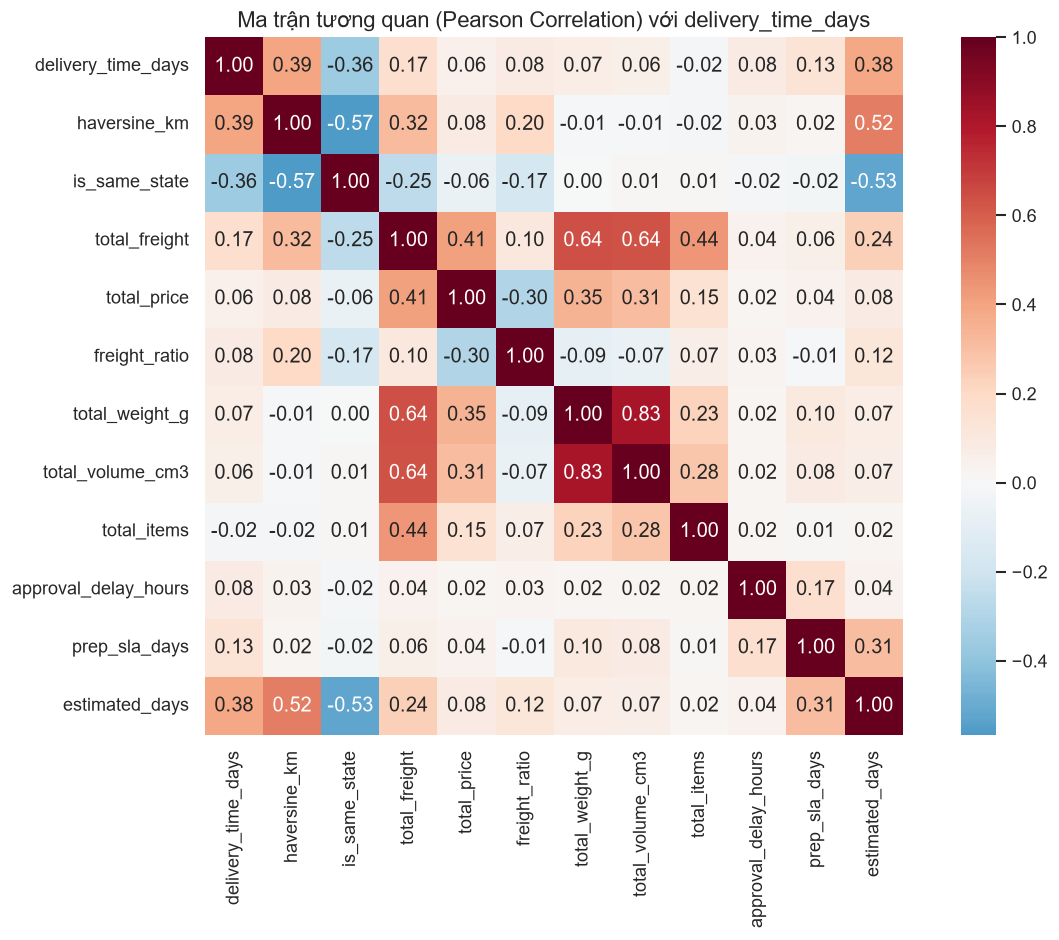

In [11]:
# Ảnh hưởng của phương thức thanh toán (boleto thường duyệt chậm hơn credit_card)
pay_stats = df_eda.groupby('primary_payment_type').agg(
    orders=('order_id', 'count'),
    mean_approval_hours=('approval_delay_hours', 'mean'),
    mean_delivery_days=('delivery_time_days', 'mean')
).sort_values('orders', ascending=False)
display(pay_stats)

# Ma trận tương quan các biến số
num_cols = [
    'delivery_time_days', 'haversine_km', 'is_same_state',
    'total_freight', 'total_price', 'freight_ratio',
    'total_weight_g', 'total_volume_cm3', 'total_items',
    'approval_delay_hours', 'prep_sla_days', 'estimated_days'
]
corr = df_eda[num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Ma trận tương quan (Pearson Correlation) với delivery_time_days')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

## 6. Tổng kết những phát hiện chính từ EDA (Key Insights cho Báo cáo)
Chạy cell dưới để in ra các con số chính xác dùng viết Chương 2 của báo cáo.

In [12]:
print('=== EDA SUMMARY REPORT ===')
print(f'1. Tổng số đơn hàng delivered hợp lệ: {len(df_eda):,}')
print(f'2. Thời gian giao hàng thực tế: Mean = {df_eda["delivery_time_days"].mean():.2f} ngày | '
      f'Median = {df_eda["delivery_time_days"].median():.2f} ngày | '
      f'Std = {df_eda["delivery_time_days"].std():.2f} ngày')
print(f'3. Baseline Olist Estimated: MAE = {olist_mae:.3f} ngày | RMSE = {olist_rmse:.3f} ngày | '
      f'Tỷ lệ giao trễ = {late_rate:.2f}%')
print(f'4. Cùng bang vs Khác bang: '
      f'Cùng bang = {df_eda[df_eda["is_same_state"]==1]["delivery_time_days"].mean():.2f} ngày | '
      f'Khác bang = {df_eda[df_eda["is_same_state"]==0]["delivery_time_days"].mean():.2f} ngày')
print(f'5. Tương quan mạnh nhất với delivery_time_days:')
print(corr['delivery_time_days'].sort_values(ascending=False).drop('delivery_time_days').head(5))

=== EDA SUMMARY REPORT ===
1. Tổng số đơn hàng delivered hợp lệ: 96,470
2. Thời gian giao hàng thực tế: Mean = 12.56 ngày | Median = 10.22 ngày | Std = 9.55 ngày
3. Baseline Olist Estimated: MAE = 12.728 ngày | RMSE = 15.122 ngày | Tỷ lệ giao trễ = 8.11%
4. Cùng bang vs Khác bang: Cùng bang = 7.95 ngày | Khác bang = 15.15 ngày
5. Tương quan mạnh nhất với delivery_time_days:
haversine_km            0.393645
estimated_days          0.383599
total_freight           0.167171
prep_sla_days           0.131340
approval_delay_hours    0.080176
Name: delivery_time_days, dtype: float64
